In [1]:
import pandas as pd
from utils.channel_model import expModel
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('./rate/registros/bitrate_vs_distancia.csv')
df

,distancia,bitrate_prom_val_pos,bitrate_incert_muestral
0,3,4.732195e+06,1.974188e+06
1,6,2.149714e+06,7.028576e+05
2,9,3.249250e+06,1.581913e+06
3,12,1.360961e+06,8.093257e+05
4,15,1.308000e+06,5.272899e+05
5,18,5.907500e+05,1.615000e+05


a = 4.277633130295451 b = 0.006346333937904484


/home/mdelcastillo/proyectos/graph_topology_control/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/home/mdelcastillo/proyectos/graph_topology_control/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


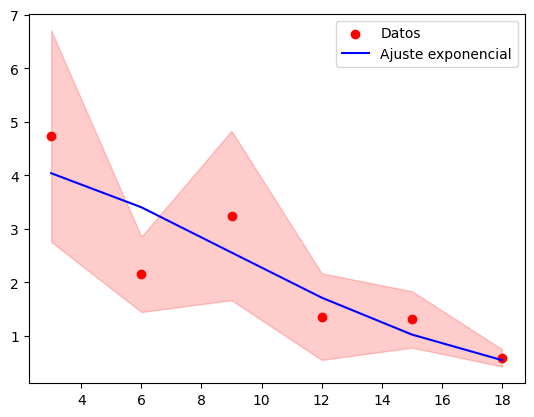

In [3]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Ejemplo de datos
x = df['distancia']
y = df['bitrate_prom_val_pos']/1e6

# Definir la función exponencial
def expo_func(x, a, b):
    return a * np.exp(-b *(x**2))

# Ajuste
popt, pcov = curve_fit(expo_func, x, y, p0=(6,0.5))

# popt contiene los parámetros a y b ajustados
a_fit, b_fit = popt
print("a =", a_fit, "b =", b_fit)

# Graficar
plt.scatter(x, y, label="Datos", color='r')
plt.fill_between(x, y+df['bitrate_incert_muestral']/1e6, y-df['bitrate_incert_muestral']/1e6, alpha=0.2, color='r')
plt.plot(x, expo_func(x, *popt), label="Ajuste exponencial", color="b")
plt.legend()
plt.show()


In [4]:
canal=expModel(power=a_fit, Ne=2, corte=1/np.sqrt(b_fit))
print (canal.rango)
print(canal.corte)

26.937753961099855
12.552740179059924


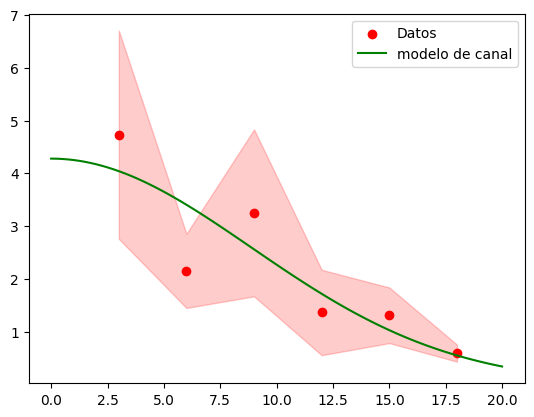

In [5]:
xc = np.zeros((80,2))
xc[:,0] = np.linspace(0, 20, 80)
yc = np.array([0,0])

def Capacity(x, y, cm):
    rate, var = cm.predict(np.vstack((x, y)))
    return rate[0,1]


    

l_cap = []
l_dev=[]
for i in range(xc.shape[0]):
    l_cap.append(Capacity(xc[i,:], yc, canal))
    l_dev.append(canal.derivative(xc[i,:],yc)[0])
# Graficar
plt.scatter(x, y, label="Datos", color='r')
plt.fill_between(x, y+df['bitrate_incert_muestral']/1e6, y-df['bitrate_incert_muestral']/1e6, alpha=0.2, color='r')
plt.plot(xc[:,0], l_cap, label="modelo de canal", color="g")
#plt.plot(xc[:,0],l_dev)
plt.legend()
plt.show()


In [6]:
import torch
from utils.connectivity_optimization import ConnectivityOpt
from test_utils.evaluation_utils import evalModelConvex
from graph_dataset_generator.graph_builder import points_to_graph

In [21]:
task_agents=3
comm_agents=2

parameters={
   'comm_agents':comm_agents,              # Number of communication agents
   'task_agents':task_agents,              # Number of task agents
   'channel':canal,  # Channel model
   'distance_factor':0.8,          # Distance factor for config sort
}
dist=parameters['distance_factor']*parameters['channel'].rango

theta1=torch.tensor(torch.pi*40/180)
theta2=torch.tensor(torch.pi*30/180)
radio=dist/2.0
task_config=torch.tensor([[0.0,0.0],[dist*torch.cos(theta1),dist*torch.sin(theta1)],[dist*torch.cos(-theta1),dist*torch.sin(-theta1)]])#x_task_gen(r=dist, n=task_agents)#
comm_config=torch.tensor([[radio*torch.cos(theta2),radio*torch.sin(theta2)],[radio*torch.cos(-theta2),radio*torch.sin(-theta2)]],requires_grad=False)#x_comm_gen(r=dist, n=comm_agents, task_agents=task_config)#
#task_config, comm_config,mnf_ini = sort_feasible_config(params=parameters,dist='poisson')
mnf_ini, flows_ini=evalModelConvex(TA=task_config, NA=comm_config, flow=True)
data_ini = points_to_graph(TA=task_config, NA=comm_config, canal=parameters['channel'],MNF=mnf_ini )
#print(f'MNF_ini: {mnf_ini}')

conOpt = ConnectivityOpt(channel_model=parameters['channel'],
                            x_task=task_config.cpu().numpy(),
                            x_comm=comm_config.cpu().numpy())
copt_config = conOpt.maximize_connectivity(viz=False, verbose=False)
xNA_fin_maxL2 = copt_config[-comm_agents:, :]
mnf_maxL2,flows_L2 = evalModelConvex(TA=task_config, NA=xNA_fin_maxL2, flow=True)

data_maxL2 = points_to_graph(TA=task_config, NA=torch.from_numpy(xNA_fin_maxL2), canal=parameters['channel'],MNF=mnf_maxL2 )
print(f"---------Resultados MNF ---------")
print("MNF ini: ", mnf_ini )
print("MNF maxL2: ", mnf_maxL2)
print("Relativo inicial: ", 100*(mnf_ini - mnf_maxL2)/abs(mnf_maxL2))

---------Resultados MNF ---------
MNF ini:  -3.820878853577488
MNF maxL2:  -4.418596671042034
Relativo inicial:  13.527322404911585


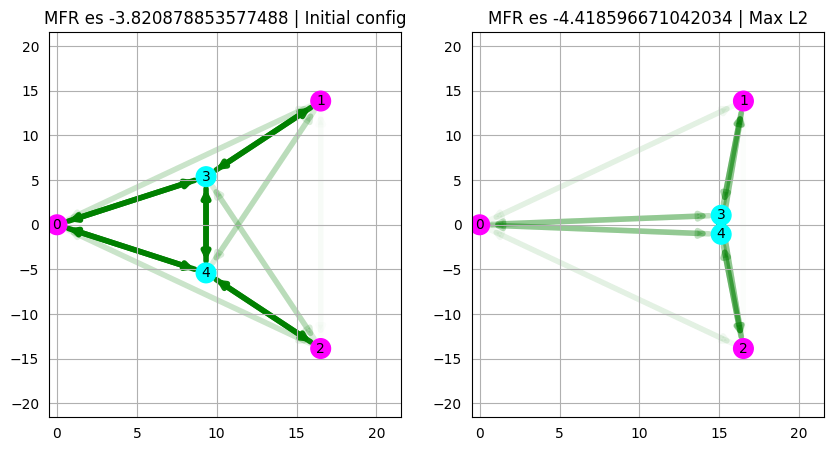

In [8]:
from utils.utils import graph_plot
fig, ax =plt.subplots(1,2, figsize=(10,5))
graph_plot(data=data_ini, ax=ax[0], title='Initial config', show=False, xlim=[-0.5,dist], ylim=[-dist,dist])
graph_plot(data=data_maxL2, ax=ax[1], title='Max L2', show=False,xlim=[-0.5,dist], ylim=[-dist,dist])
#graph_plot(data=data_modelY, ax=ax[2], title='Model Y', show=False,xlim=[-0.5,dist], ylim=[-dist,dist])
#

In [20]:
parameters['space_size'] = canal.rango * ((5/3.0)**0.5)
print(canal.rango)
print(parameters['space_size'] )

26.937753961099855
34.77649082519087


In [24]:
print(flows_ini['flows_ak'])
print(flows_L2['flows_ak'])

[0.02518089 0.02518089 0.01659013 0.02517206 0.02517206 0.01659013]
[0.01098748 0.01098753 0.01449806 0.01098683 0.01098688 0.01449806]


<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

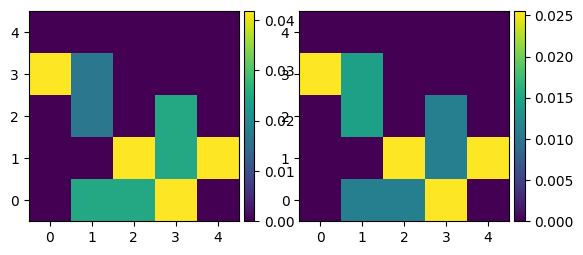

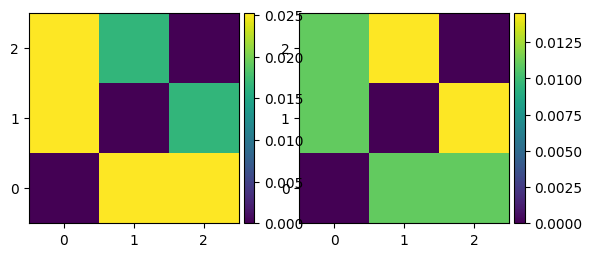

In [35]:
from test_utils.evaluation_utils import plot_ak_matrix, plot_rates_matrix
fig, ax=plt.subplots(1,2)
rate_ini=plot_rates_matrix(task_config, comm_config,canal, flows_ini['edge_rate'], ax=ax[0], norm=False)
rate_L2 = plot_rates_matrix(task_config, comm_config, canal, flows_L2['edge_rate'], ax=ax[1],norm=False)
plt.tight_layout

fig, ax=plt.subplots(1,2)
rate_ini=plot_ak_matrix(task_config.shape[0], flows_ini['flows_ak'], ax=ax[0], norm=False)
rate_L2 = plot_ak_matrix(task_config.shape[0], flows_L2['flows_ak'], ax=ax[1],norm=False)
plt.tight_layout